## Enter your name and student ID here
Name:Aslı Dağdelen

ID:210402814

In [ ]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

# 1. Loading Data

In [ ]:
background = pd.read_csv("/content/sample_data/Background.csv")
background
grades = pd.read_csv("/content/sample_data/Grades.csv")

In [ ]:
grades.head(5)

,ID,math score,reading score,writing score
0,0,72,72,74
1,1,69,90,88
2,2,90,95,93
3,3,47,57,44
4,4,76,78,75


# 2. Columns & Rows reporting

In [ ]:
#print names of columns and the number of rows for background dataframe
background_columns = print(background.columns)

Index(['ID', 'gender', 'race/ethnicity', 'parental level of education',
       'lunch', 'test preparation course'],
      dtype='object')


In [ ]:
background_rows = print(len(background))

1000


In [ ]:
#print names of columns and the number of rows for grades dataframe
grades_column = print(grades.columns)

Index(['ID', 'math score', 'reading score', 'writing score'], dtype='object')


In [ ]:
grades_rows = print(len(grades))

1000


# 3. Average grade

In [ ]:
#Calculate and add “average score" to grades
average_grade = 0.4* grades['math score']+ grades['reading score']* 0.3 + grades['writing score']*0.3
grades["Average Score"] = average_grade


grades.head(5)

,ID,math score,reading score,writing score,Average Score
0,0,72,72,74,72.6
1,1,69,90,88,81.0
2,2,90,95,93,92.4
3,3,47,57,44,49.1
4,4,76,78,75,76.3


# 4. Sorting

In [ ]:
#sorting
grades.sort_values(by=["Average Score"], ascending=False).head(5)



,ID,math score,reading score,writing score,Average Score
962,962,100,100,100,100.0
916,916,100,100,100,100.0
458,458,100,100,100,100.0
114,114,99,100,100,99.6
712,712,98,100,99,98.9


In [ ]:
# Find and print the number of students who received an average score of 95 and higher
higher_than_95 = grades[(grades['Average Score']>= 95)]
len(higher_than_95)

20

# 5. Scatter Plots

<Axes: xlabel='math score', ylabel='reading score'>

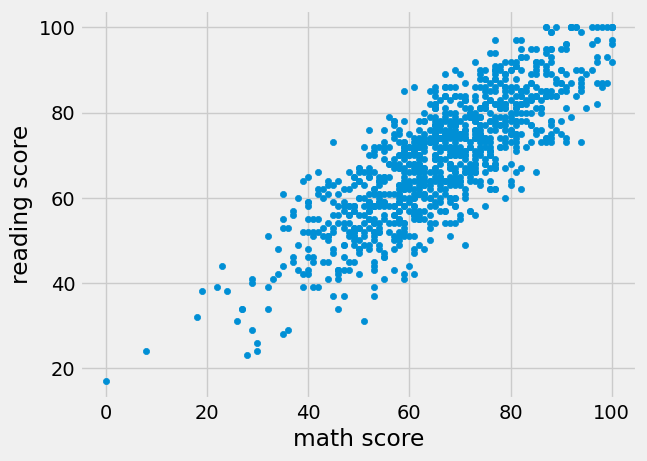

In [ ]:
grades.plot.scatter("math score", "reading score")

<Axes: xlabel='writing score', ylabel='reading score'>

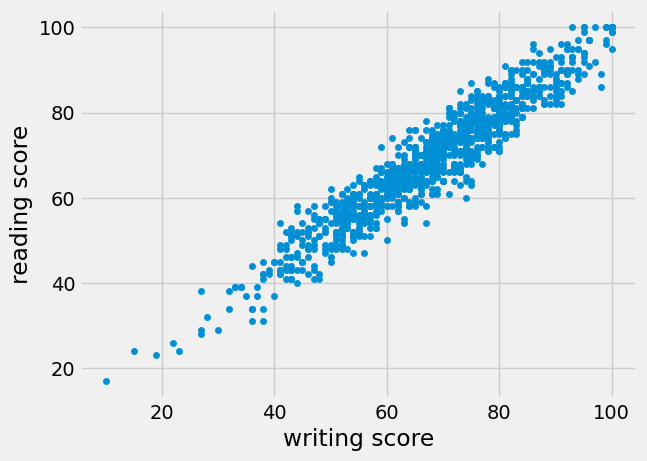

In [ ]:
grades.plot.scatter("writing score", "reading score")

<Axes: xlabel='math score', ylabel='writing score'>

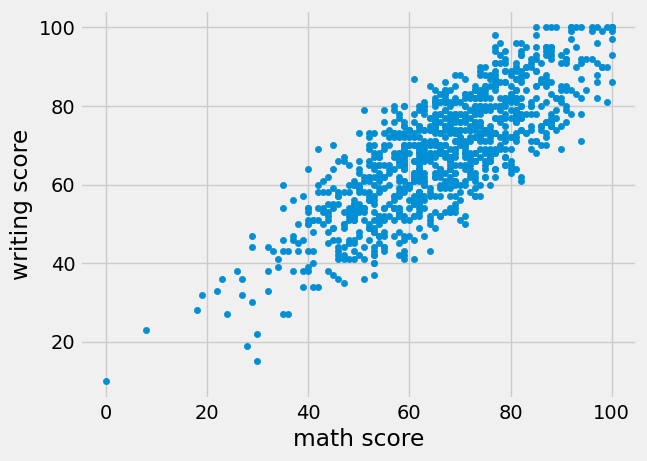

In [ ]:
grades.plot.scatter("math score", "writing score")

The scatter plot data shows that reading and writing scores are more in relation compared to math scores.

# 6. Gender Analysis (Bar Chart)

In [ ]:
analysis = background.merge(grades)
analysis_female= analysis[(analysis["gender"] == "female")]
analysis_female_mean=analysis_female.mean()
analysis_female_mean

ID               511.484556
math score        63.633205
reading score     72.608108
writing score     72.467181
Average Score     68.975869
dtype: float64

In [ ]:
analysis_male= analysis[(analysis["gender"]== "male")]
analysis_male_mean = analysis_male.mean()
analysis_male_mean

ID               486.620332
math score        68.728216
reading score     65.473029
writing score     63.311203
Average Score     66.126556
dtype: float64

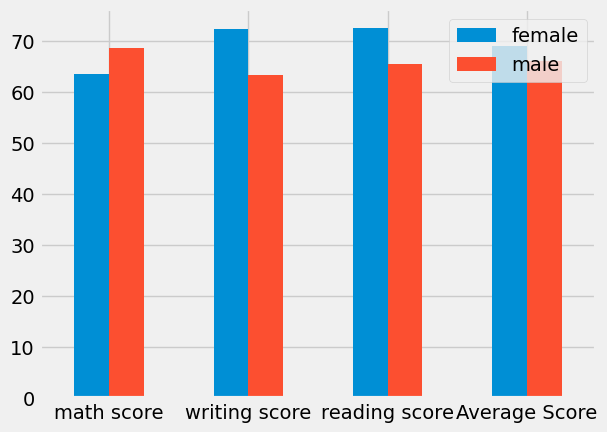

In [ ]:
female= analysis_female_mean
male = analysis_male_mean
index = ['math score', 'writing score', 'reading score', 'Average Score']
Bar_plot = pd.DataFrame({'female': female,
                   'male': male}, index=index)
ax = Bar_plot.plot.bar(rot=0)

The analysis shows that the male students had better scores in math exam however, female students had better scores in writing and reading exams. Moreover, female students had a better mean of average score.

# 7. Letter Grade

In [ ]:
#add "letter grade" columns
def letter_score(average_grade):
  if average_grade >= 90:
    letter_grade = "A"
    return letter_grade
  elif average_grade >=80 and average_grade < 90:
    letter_grade = "B"
    return letter_grade
  elif average_grade >= 70 and average_grade < 80:
    letter_grade = "C"
    return letter_grade
  elif average_grade >= 60 and average_grade < 70:
    letter_grade = "D"
    return letter_grade
  else:
    letter_grade = "F"
    return letter_grade

letter_grade = average_grade.apply(letter_score)
grades["Letter Grade"] = letter_grade


grades.head(5)

,ID,math score,reading score,writing score,Average Score,Letter Grade
0,0,72,72,74,72.6,C
1,1,69,90,88,81.0,B
2,2,90,95,93,92.4,A
3,3,47,57,44,49.1,F
4,4,76,78,75,76.3,C


<Axes: xlabel='Letter Grade'>

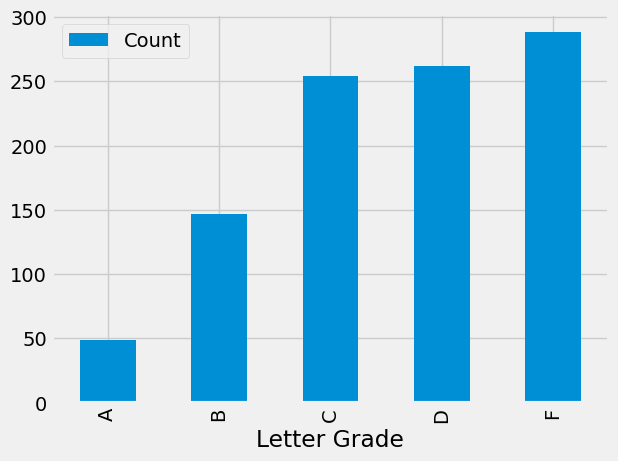

In [ ]:
#plot distributio nof letter grades
letter_grade_dist=grades.groupby("Letter Grade").size()
dist_of_letter_grade = pd.DataFrame(letter_grade_dist, columns= ["Count"]).reset_index()
dist_of_letter_grade.plot.bar("Letter Grade", "Count")

# 8. Race/Ethnicity Analysis

<Axes: xlabel='race/ethnicity'>

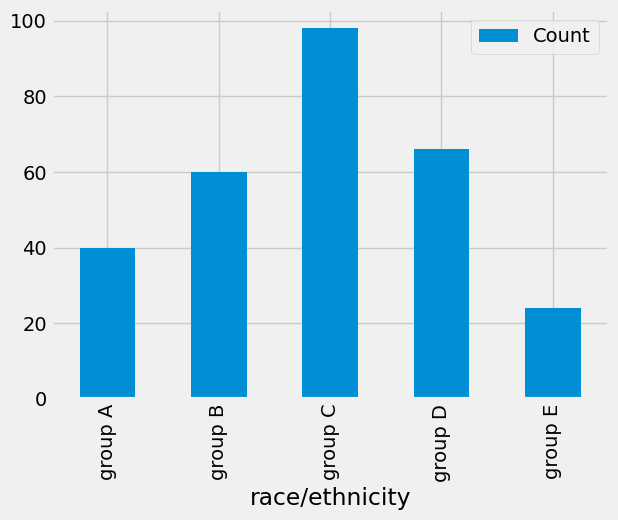

In [ ]:
analysis = background.merge(grades)
analysis_race= analysis[(analysis["Letter Grade"]== "F")]
race_grade_dist=analysis_race.groupby("race/ethnicity", ).size()
race_grade_dist = pd.DataFrame(race_grade_dist, columns= ["Count"]).reset_index()
race_grade_dist.plot.bar("race/ethnicity", "Count")

# 9. Score Distributions based on Test Preparation

In [ ]:
completed_course = analysis[(analysis["test preparation course"] == "completed")]


array([[<Axes: title={'center': 'Average Score'}>]], dtype=object)

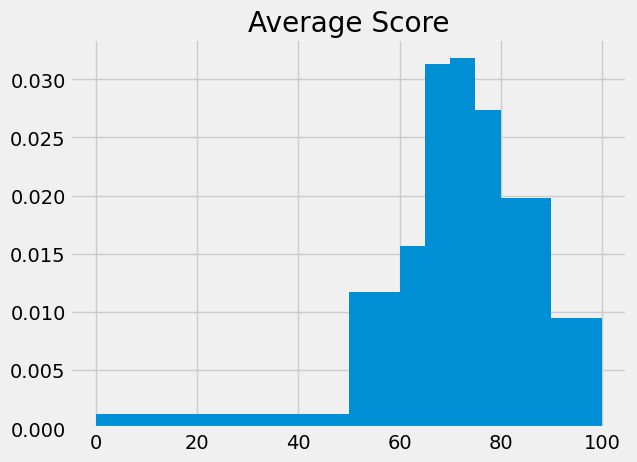

In [ ]:
completed_course.hist("Average Score", bins = [0 , 50 , 60 , 65 , 70, 75, 80, 90, 100], density= True)

array([[<Axes: title={'center': 'Average Score'}>]], dtype=object)

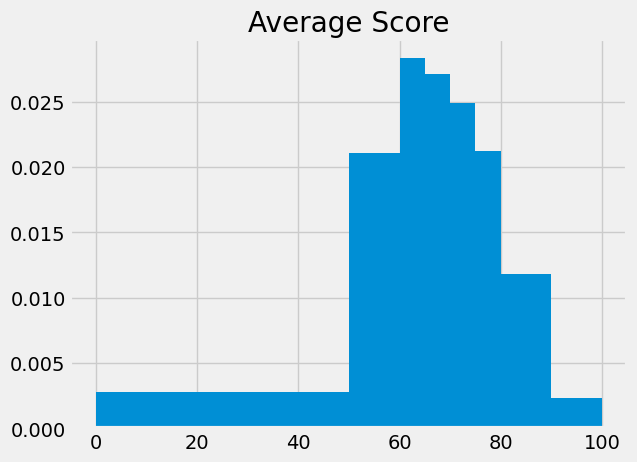

In [ ]:
not_completed_course = analysis[(analysis["test preparation course"] == "none")]
not_completed_course.hist("Average Score",bins = [0 , 50 , 60 , 65 , 70, 75, 80, 90, 100], density= True)

# 10. Effect of Parents' Education Level

In [ ]:
grades_A = analysis[(analysis["Letter Grade"] == "A")]
grades_B = analysis[(analysis["Letter Grade"] == "B")]
grades_C = analysis[(analysis["Letter Grade"] == "C")]
grades_D = analysis[(analysis["Letter Grade"] == "D")]
grades_F = analysis[(analysis["Letter Grade"] == "F")]

In [ ]:
hs_parent_A = grades_A[(grades_A["parental level of education"] == "high school")]
hs_parent_B = grades_B[(grades_B["parental level of education"] == "high school")]
hs_parent_C = grades_C[(grades_C["parental level of education"] == "high school")]
hs_parent_D = grades_D[(grades_D["parental level of education"] == "high school")]
hs_parent_F = grades_F[(grades_F["parental level of education"] == "high school")]

In [ ]:
percentage_hs_A_B= 100*(len(hs_parent_B)+len(hs_parent_A))/(len(hs_parent_B)+len(hs_parent_A)+len(hs_parent_C)+len(hs_parent_D)+len(hs_parent_F))
percentage_hs_C_D_F = 100-percentage_hs_A_B

In [ ]:
col_parent_A = grades_A[(grades_A["parental level of education"] != "high school")]
col_parent_B = grades_B[(grades_B["parental level of education"] != "high school")]
col_parent_C = grades_C[(grades_C["parental level of education"] != "high school")]
col_parent_D = grades_D[(grades_D["parental level of education"] != "high school")]
col_parent_F = grades_F[(grades_F["parental level of education"] != "high school")]

In [ ]:
percentage_col_A_B = 100*(len(col_parent_B)+len(col_parent_A))/(len(col_parent_B)+len(col_parent_A)+len(col_parent_C)+len(col_parent_D)+len(col_parent_F))
percentage_col_C_D_F = 100-percentage_col_A_B
percentage_col_C_D_F

77.98507462686567

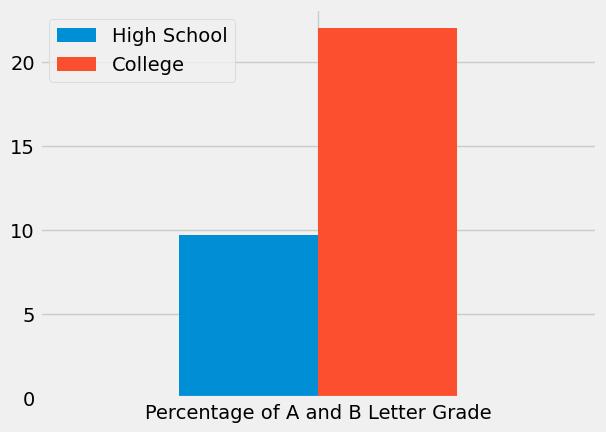

In [ ]:
high_school= percentage_hs_A_B
college = percentage_col_A_B
index = ['Percentage of A and B Letter Grade']
Bar_plot = pd.DataFrame({'High School': high_school,
                   'College': college}, index=index)
ax = Bar_plot.plot.bar(rot=0)

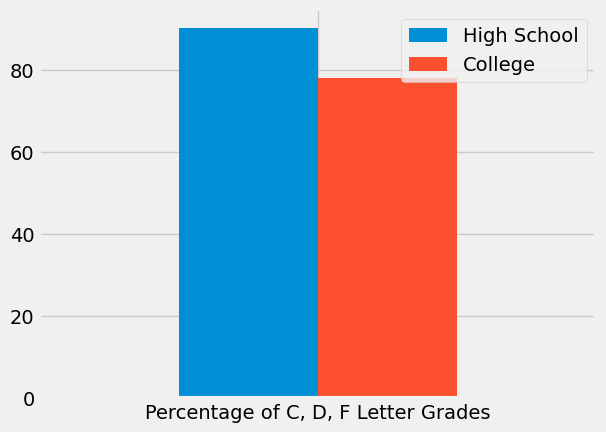

In [ ]:
high_school= percentage_hs_C_D_F
college = percentage_col_C_D_F
index = ['Percentage of C, D, F Letter Grades']
Bar_plot = pd.DataFrame({'High School': high_school,
                   'College': college}, index=index)
ax = Bar_plot.plot.bar(rot=0)

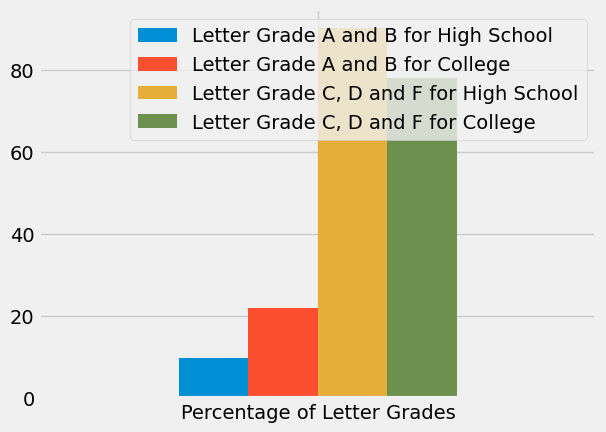

In [ ]:
high_school_A_B= percentage_hs_A_B
college_A_B = percentage_col_A_B
high_school_C_D_F = percentage_hs_C_D_F
college_C_D_F = percentage_col_C_D_F
index = ['Percentage of Letter Grades' ]
Bar_plot = pd.DataFrame({'Letter Grade A and B for High School': high_school_A_B,
                   'Letter Grade A and B for College': college_A_B,
                   'Letter Grade C, D and F for High School': high_school_C_D_F ,
                   'Letter Grade C, D and F for College': college_C_D_F}, index=index)
ax = Bar_plot.plot.bar(rot=0)

It could be seen that students who had parents that had higher education than high school received letter grades A or B more compared to the students whose parents had not have higher education than high school. For letter grades C, D and F, the difference is not as noticable as A or B letter grades however, the opposite could be said about the parental education level.

# 11. Gender- Ethnicity	 Grid

In [ ]:
grades_A.head(5)

,ID,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average Score,Letter Grade
2,2,female,group B,master's degree,standard,none,90,95,93,92.4,A
6,6,female,group B,some college,standard,completed,88,95,92,91.3,A
104,104,male,group C,some college,standard,completed,98,86,90,92.0,A
106,106,female,group D,master's degree,standard,none,87,100,100,94.8,A
114,114,female,group E,bachelor's degree,standard,completed,99,100,100,99.6,A


In [ ]:
groupA = grades_A.groupby(['gender', 'race/ethnicity']).size()
groupA

gender  race/ethnicity
female  group A            1
        group B            5
        group C            6
        group D           11
        group E           11
male    group A            3
        group B            2
        group C            6
        group D            1
        group E            3
dtype: int64